Берем наши данные из EDA. Категориальные и числовые признаки по отдельности.

In [ ]:
import pandas as pd

df_train_cont = pd.read_csv('DS/train_cont.csv')
df_train_cat = pd.read_csv('DS/train_cat.csv')

df_test_cont = pd.read_csv('DS/test_cont.csv')
df_test_cat = pd.read_csv('DS/test_cat.csv')

X_train = pd.concat([df_train_cont, df_train_cat], axis=1)
X_test = pd.concat([df_test_cont, df_test_cat], axis=1)

In [4]:
X_train.head()

,Survived,Pclass,Age,Fare,Family,Age_missing,Sex,Cabin_missing
0,0,3,22.0,7.2500,1,0,0,1
1,1,1,38.0,71.2833,1,0,1,0
2,1,3,26.0,7.9250,0,0,1,1
3,1,1,35.0,53.1000,1,0,1,0
4,0,3,35.0,8.0500,0,0,0,1


In [7]:
y_train = X_train.loc[:, "Survived"]
X_train.drop(columns=["Survived"], inplace=True)

y_test = pd.read_csv('DS/gender_submission.csv')
y_test = y_test.loc[:, "Survived"]

Отмасштабировать данные

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

Логистическая регрессия.

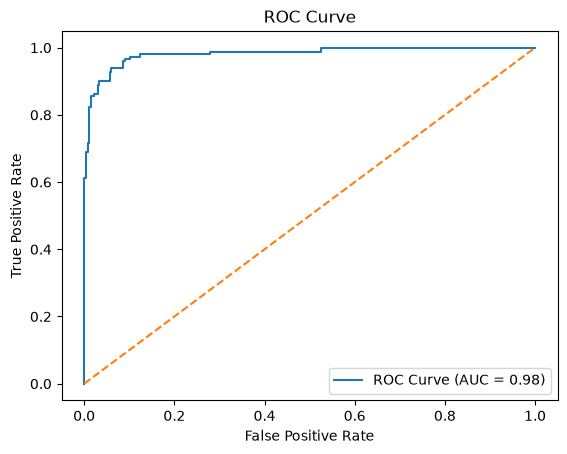

Accuracy: 0.935 
 Precision: 0.903 
 Recall: 0.921 
 F1 Score: 0.912 
 AUC: 0.982


In [62]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix,precision_score, recall_score,f1_score,roc_curve, roc_auc_score

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

y_prob = log_reg.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--") 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print(f"Accuracy: {round(accuracy, 3)} \n Precision: {round(precision, 3)} \n Recall: {round(recall, 3)} \n F1 Score: {round(f1, 3)} \n AUC: {round(roc_auc, 3)}")

In [30]:
import shap
import numpy as np

explainer = shap.LinearExplainer(log_reg, X_train)
shap_values = explainer(X_test)

values = shap_values.values[..., 1] if shap_values.values.ndim == 3 else shap_values.values
importance = abs(values).mean(axis=0)
shap_importance = (
    pd.Series(importance, index=X_test.columns)
    .sort_values(ascending=False)
)
print(shap_importance)

Background dataset has 891 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=891 when initializing the masker.


Sex              1.235105
Pclass           0.632809
Age              0.338782
Cabin_missing    0.260039
Family           0.252674
Fare             0.083560
Age_missing      0.067935
dtype: float64


Дерево решений

In [59]:
from sklearn import tree

tree_clf = tree.DecisionTreeClassifier(max_depth=3)
tree_clf.fit(X_train, y_train)

y_pred = tree_clf.predict(X_test)

[Text(0.5, 0.875, 'x[5] <= 0.309\ngini = 0.473\nsamples = 891\nvalue = [549, 342]'),
 Text(0.25, 0.625, 'x[6] <= -0.645\ngini = 0.306\nsamples = 577\nvalue = [468, 109]'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'x[1] <= -0.912\ngini = 0.487\nsamples = 107\nvalue = [62.0, 45.0]'),
 Text(0.0625, 0.125, 'gini = 0.0\nsamples = 8\nvalue = [0, 8]'),
 Text(0.1875, 0.125, 'gini = 0.468\nsamples = 99\nvalue = [62, 37]'),
 Text(0.375, 0.375, 'x[1] <= -1.987\ngini = 0.235\nsamples = 470\nvalue = [406, 64]'),
 Text(0.3125, 0.125, 'gini = 0.459\nsamples = 14\nvalue = [5, 9]'),
 Text(0.4375, 0.125, 'gini = 0.212\nsamples = 456\nvalue = [401, 55]'),
 Text(0.75, 0.625, 'x[0] <= 0.229\ngini = 0.383\nsamples = 314\nvalue = [81.0, 233.0]'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'x[1] <= -2.064\ngini = 0.1\nsamples = 170\nvalue = [9, 161]'),
 Text(0.5625, 0.125, 'gini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.6875, 0.125, 'gini = 0.091\nsamples = 168\nvalue = [8, 160]'),
 Text(

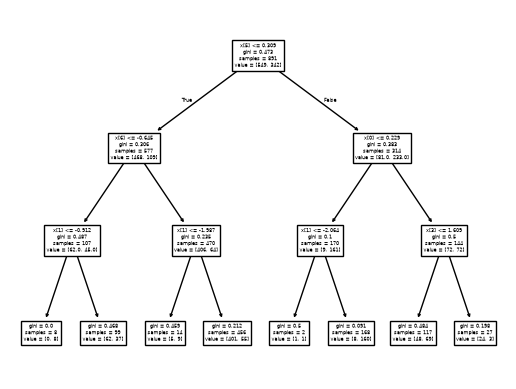

In [60]:
tree.plot_tree(tree_clf)

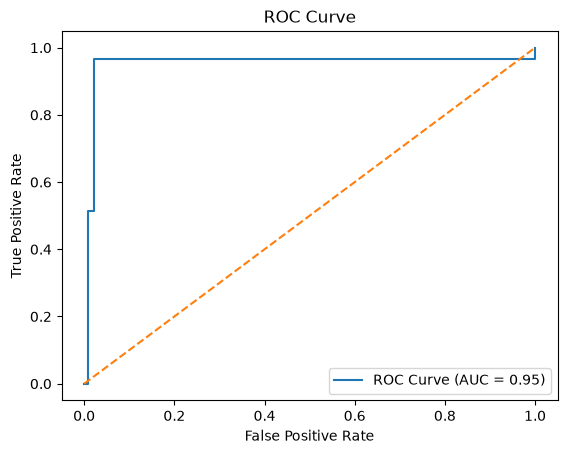

Accuracy: 0.969 
 Precision: 0.96 
 Recall: 0.954 
 F1 Score: 0.957 
 AUC: 0.953


In [61]:
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

y_prob = tree_clf.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--") 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print(f"Accuracy: {round(accuracy, 3)} \n Precision: {round(precision, 3)} \n Recall: {round(recall, 3)} \n F1 Score: {round(f1, 3)} \n AUC: {round(roc_auc, 3)}")

In [31]:
explainer = shap.TreeExplainer(tree_clf, X_train)
shap_values = explainer(X_test)

values = shap_values.values[..., 1] if shap_values.values.ndim == 3 else shap_values.values
importance = abs(values).mean(axis=0)
shap_importance = (
    pd.Series(importance, index=X_test.columns)
    .sort_values(ascending=False)
)
print(shap_importance)

Background dataset has 891 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=891 when initializing the masker.


Sex              0.248729
Pclass           0.070291
Cabin_missing    0.067851
Age              0.022266
Family           0.016458
Fare             0.000000
Age_missing      0.000000
dtype: float64


Случайный лес

In [57]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

y_pred = rf_clf.predict(X_test)

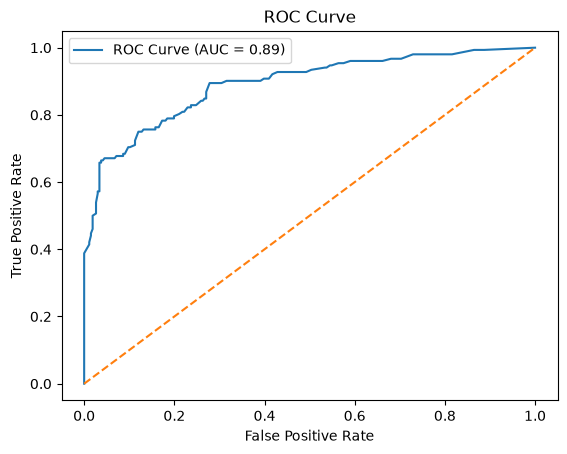

Accuracy: 0.813 
 Precision: 0.737 
 Recall: 0.757 
 F1 Score: 0.747 
 AUC: 0.891


In [58]:
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

y_prob = rf_clf.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--") 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print(f"Accuracy: {round(accuracy, 3)} \n Precision: {round(precision, 3)} \n Recall: {round(recall, 3)} \n F1 Score: {round(f1, 3)} \n AUC: {round(roc_auc, 3)}")

In [34]:
explainer = shap.TreeExplainer(rf_clf, X_train)
shap_values = explainer(X_test)

values = shap_values.values[..., 1] if shap_values.values.ndim == 3 else shap_values.values
importance = abs(values).mean(axis=0)
shap_importance = (
    pd.Series(importance, index=X_test.columns)
    .sort_values(ascending=False)
)
print(shap_importance)

Background dataset has 891 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=891 when initializing the masker.


Sex              0.207178
Pclass           0.083339
Fare             0.062066
Age              0.055118
Cabin_missing    0.046164
Family           0.030308
Age_missing      0.019791
dtype: float64


XBoost

In [55]:
import xgboost as xgb

model = xgb.XGBClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

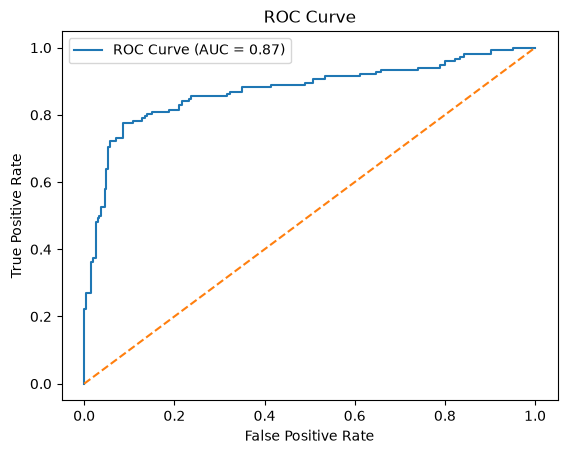

Accuracy: 0.849 
 Precision: 0.799 
 Recall: 0.783 
 F1 Score: 0.791 
 AUC: 0.872


In [56]:
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--") 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print(f"Accuracy: {round(accuracy, 3)} \n Precision: {round(precision, 3)} \n Recall: {round(recall, 3)} \n F1 Score: {round(f1, 3)} \n AUC: {round(roc_auc, 3)}")

In [37]:
explainer = shap.TreeExplainer(model, X_train)
shap_values = explainer(X_test)

values = shap_values.values[..., 1] if shap_values.values.ndim == 3 else shap_values.values
importance = abs(values).mean(axis=0)
shap_importance = (
    pd.Series(importance, index=X_test.columns)
    .sort_values(ascending=False)
)
print(shap_importance)

Background dataset has 891 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=891 when initializing the masker.


Sex              1.798287
Pclass           0.866633
Fare             0.861400
Age              0.754609
Family           0.314606
Cabin_missing    0.313697
Age_missing      0.164128
dtype: float64


CatBoost

In [53]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

Learning rate set to 0.081009
0:	learn: 0.6604919	total: 1.02ms	remaining: 101ms
1:	learn: 0.6320562	total: 5.04ms	remaining: 247ms
2:	learn: 0.6083702	total: 5.75ms	remaining: 186ms
3:	learn: 0.5861660	total: 6.4ms	remaining: 154ms
4:	learn: 0.5683232	total: 7.08ms	remaining: 135ms
5:	learn: 0.5520122	total: 7.42ms	remaining: 116ms
6:	learn: 0.5365393	total: 8.22ms	remaining: 109ms
7:	learn: 0.5234519	total: 8.82ms	remaining: 101ms
8:	learn: 0.5114007	total: 9.42ms	remaining: 95.3ms
9:	learn: 0.5004639	total: 10ms	remaining: 90.3ms
10:	learn: 0.4908633	total: 10.8ms	remaining: 87.5ms
11:	learn: 0.4815629	total: 11.4ms	remaining: 83.7ms
12:	learn: 0.4763157	total: 11.6ms	remaining: 77.6ms
13:	learn: 0.4683412	total: 12.3ms	remaining: 75.8ms
14:	learn: 0.4627287	total: 13ms	remaining: 73.5ms
15:	learn: 0.4560617	total: 13.6ms	remaining: 71.4ms
16:	learn: 0.4516094	total: 14.2ms	remaining: 69.2ms
17:	learn: 0.4460662	total: 14.8ms	remaining: 67.3ms
18:	learn: 0.4411746	total: 15.4ms	rema

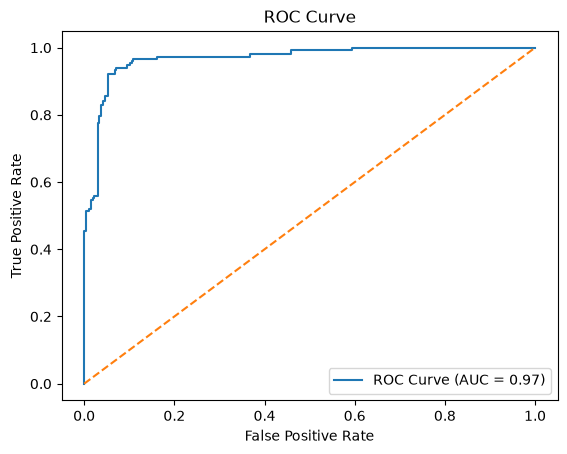

Accuracy: 0.931 
 Precision: 0.907 
 Recall: 0.901 
 F1 Score: 0.904 
 AUC: 0.969


In [54]:
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--") 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print(f"Accuracy: {round(accuracy, 3)} \n Precision: {round(precision, 3)} \n Recall: {round(recall, 3)} \n F1 Score: {round(f1, 3)} \n AUC: {round(roc_auc, 3)}")

In [40]:
explainer = shap.TreeExplainer(model, X_train)
shap_values = explainer(X_test)

values = shap_values.values[..., 1] if shap_values.values.ndim == 3 else shap_values.values
importance = abs(values).mean(axis=0)
shap_importance = (
    pd.Series(importance, index=X_test.columns)
    .sort_values(ascending=False)
)
print(shap_importance)

Background dataset has 891 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=891 when initializing the masker.


Sex              1.211023
Pclass           0.423035
Fare             0.264891
Age              0.230667
Cabin_missing    0.225056
Family           0.151033
Age_missing      0.030469
dtype: float64


KNN

In [51]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

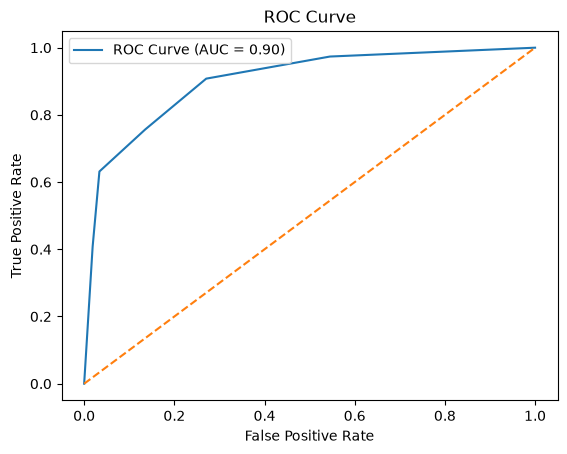

Accuracy: 0.825 
 Precision: 0.762 
 Recall: 0.757 
 F1 Score: 0.759 
 AUC: 0.902


In [52]:
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--") 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print(f"Accuracy: {round(accuracy, 3)} \n Precision: {round(precision, 3)} \n Recall: {round(recall, 3)} \n F1 Score: {round(f1, 3)} \n AUC: {round(roc_auc, 3)}")

In [45]:
explainer = shap.KernelExplainer(model.predict_proba, shap.sample(X_train, 100))
shap_values = explainer.shap_values(X_test.iloc[:50])

values = shap_values[..., 1] if shap_values.ndim == 3 else shap_values
importance = abs(values).mean(axis=0)
shap_importance = (
    pd.Series(importance, index=X_test.columns)
    .sort_values(ascending=False)
)
print(shap_importance)

100%|██████████| 50/50 [00:00<00:00, 53.90it/s]

Fare             0.186172
Age              0.109349
Sex              0.042490
Family           0.021325
Pclass           0.009192
Age_missing      0.006542
Cabin_missing    0.005176
dtype: float64


FNN

In [87]:
import tensorflow as tf
from tensorflow.keras import layers, models

n_features = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])

model.fit(X_train, y_train, epochs=100)

Epoch 1/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 891us/step - accuracy: 0.5668 - auc: 0.5587 - loss: 0.6684 
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 969us/step - accuracy: 0.6768 - auc: 0.7111 - loss: 0.6087
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 915us/step - accuracy: 0.7363 - auc: 0.7713 - loss: 0.5695
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 918us/step - accuracy: 0.7598 - auc: 0.8040 - loss: 0.5380
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 956us/step - accuracy: 0.7722 - auc: 0.8228 - loss: 0.5130
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 900us/step - accuracy: 0.7946 - auc: 0.8410 - loss: 0.4923
Epoch 7/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 921us/step - accuracy: 0.8013 - auc: 0.8514 - loss: 0.4755
Epoch 8/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 908us/step - accuracy: 0.8081 - auc: 0.8549 - loss: 0.4630
Epoch 9/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 980us/step - accuracy: 0.8047 - auc: 0.8579 - loss: 0.4540
Epoch 10/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 947us/step - accuracy: 0.8070 - auc: 0.8603 - l

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 933us/step


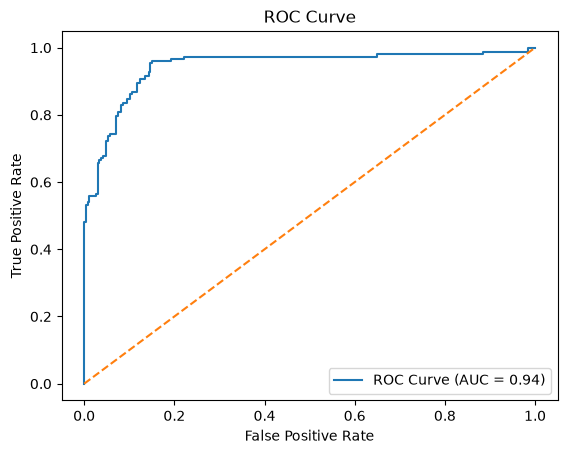

Accuracy: 0.933 
 Precision: 0.908 
 Recall: 0.908 
 F1 Score: 0.908 
 AUC: 0.944


In [90]:
y_prob = model.predict(X_test).ravel()
y_pred = (y_pred > 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--") 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print(f"Accuracy: {round(accuracy, 3)} \n Precision: {round(precision, 3)} \n Recall: {round(recall, 3)} \n F1 Score: {round(f1, 3)} \n AUC: {round(roc_auc, 3)}")

In [95]:
explainer = shap.KernelExplainer(model, X_train)
shap_values = explainer(X_test)
values = shap_values.values[..., 0]
importance = abs(values).mean(axis=0)
feature_names = ["Pclass", "Age", "Fare", "Family", "Age_missing", "Sex", "Cabin_missing"]
shap_importance = pd.Series(importance, index=feature_names).sort_values(ascending=False)
print(shap_importance)

Using 891 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
100%|██████████| 418/418 [00:04<00:00, 104.03it/s]

Sex              0.224363
Pclass           0.101098
Age              0.047377
Cabin_missing    0.040072
Family           0.035614
Fare             0.028513
Age_missing      0.014558
dtype: float64


RNN

In [98]:
X_train_rnn = X_train.reshape(-1, n_features, 1)
X_test_rnn = X_test.reshape(-1, n_features, 1)

model = models.Sequential([
    layers.Input(shape=(n_features, 1)),
    layers.LSTM(16),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
model.fit(X_train_rnn, y_train, epochs=50, validation_split=0.2)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5927 - auc: 0.5193 - loss: 0.6897 - val_accuracy: 0.6145 - val_auc: 0.5934 - val_loss: 0.6818
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5969 - auc: 0.5762 - loss: 0.6796 - val_accuracy: 0.6257 - val_auc: 0.6346 - val_loss: 0.6683
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5997 - auc: 0.6010 - loss: 0.6700 - val_accuracy: 0.6257 - val_auc: 0.6467 - val_loss: 0.6550
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6067 - auc: 0.6265 - loss: 0.6612 - val_accuracy: 0.6313 - val_auc: 0.6778 - val_loss: 0.6429
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6081 - auc: 0.7015 - loss: 0.6547 - val_accuracy: 0.6313 - val_auc: 0.7541 - val_loss: 0.6337
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6081 - auc: 0.7320 - loss: 0.6468 - val_accuracy: 0.6313 - val_auc: 0.7767 - val_loss: 0.6217
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - 

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


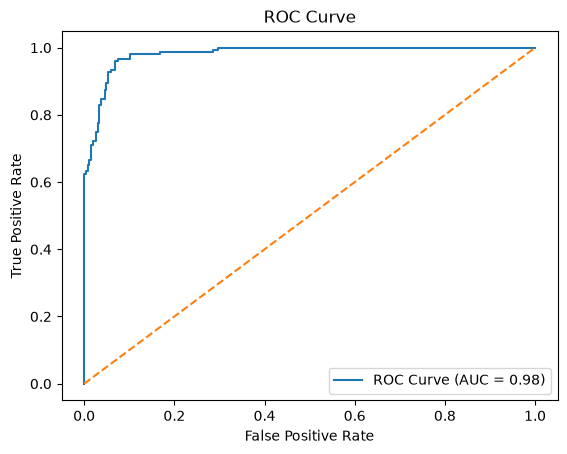

Accuracy: 0.933 
 Precision: 0.908 
 Recall: 0.908 
 F1 Score: 0.908 
 AUC: 0.982


In [99]:
y_prob = model.predict(X_test_rnn).ravel()
y_pred = (y_pred > 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--") 
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print(f"Accuracy: {round(accuracy, 3)} \n Precision: {round(precision, 3)} \n Recall: {round(recall, 3)} \n F1 Score: {round(f1, 3)} \n AUC: {round(roc_auc, 3)}")

In [101]:
def predict_rnn(X):
    X = np.asarray(X).reshape(-1, n_features, 1)
    return model.predict(X).ravel()

background = X_train[np.random.choice(len(X_train), 50, replace=False)]
explainer = shap.KernelExplainer(predict_rnn, background)

shap_values = explainer.shap_values(X_test[:30])
importance = np.abs(np.squeeze(np.array(shap_values))).mean(axis=0)

feature_names = ["Pclass", "Age", "Fare", "Family", "Age_missing", "Sex", "Cabin_missing"]
shap_importance = pd.Series(importance, index=feature_names).sort_values(ascending=False)
print(shap_importance)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


  0%|          | 0/30 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 471us/step


  3%|▎         | 1/30 [00:00<00:05,  5.50it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step


...

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 467us/step


 97%|█████████▋| 29/30 [00:05<00:00,  5.63it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
197/197 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step


100%|██████████| 30/30 [00:05<00:00,  5.60it/s]

Sex              0.217595
Pclass           0.109732
Age              0.046080
Cabin_missing    0.039616
Family           0.026061
Fare             0.022377
Age_missing      0.007874
dtype: float64
